# PHYS 763 HW4b: From IQ Blobs to Readout Errors
Fall 2026 - due Monday, November 2, 2026. **15 points**, separate from written HW4.

Use the settings and local-state checkpoint procedure in the PDF handout to collect IQ data from two working qubits. Start QUAlibrate with `uv run qualibrate start` and access its browser interface at http://127.0.0.1:8001 (the default address). Run `07_iq_blobs`, one selected qubit at a time, with 1000 shots per preparation class.

This notebook analyzes your saved runs. Use the Qolab Python environment as your notebook kernel. Complete the plots, classifier, and written answers below.

In [29]:
from pathlib import Path
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

## 1. IQ clouds and experimental record (4 points)

Submit your raw datasets, saved run parameters, and completed notebook with answers to every part of the PDF. Keep tokens and credentials out of the submission.

| Qubit | Run ID | Date/time | Commit | Shots per class | Reset mode | Local checkpoint/restoration |
| --- | --- | --- | --- | --- | --- | --- |
| | | | | | | |
| | | | | | | |

Explain the two preparation sequences. The labels g/e identify the intended preparation.

Each run saves `ds_raw.h5` in the project's data directory, under `qualibration_graphs/superconducting/calibrations/1Q_calibrations/data/`. Load this file for your analysis. Restore the saved starting state after each acquisition as described in the handout.

The raw IQ variables are **Ig, Qg, Ie, Qe**, indexed by **qubit** and **n_runs**. They are individual integrated samples, already in **volts**, even when unit metadata are absent. Multiply all coordinates by 1000 if plotting in millivolts.

In [30]:
def load_iq(path):
    """Load a current 07_iq_blobs raw dataset; no hardware imports."""
    path = Path(path).expanduser()
    if not path.is_file():
        raise FileNotFoundError(f"Choose the ds_raw.h5 from your saved IQ run: {path}")
    with xr.open_dataset(path) as opened:
        ds = opened.load()
    required = {"Ig", "Qg", "Ie", "Qe"}
    if not required.issubset(ds.data_vars) or "qubit" not in ds.coords:
        raise ValueError("Expected Ig, Qg, Ie, Qe and named qubits from 07_iq_blobs.")
    return ds


def iq_samples(ds, qubit):
    """Return arrays of shape (number of shots, 2), with columns I and Q in V."""
    if qubit not in ds.qubit.values:
        raise ValueError(f"Unknown qubit {qubit!r}; choose from {ds.qubit.values.tolist()}")
    selected = ds.sel(qubit=qubit)
    values = {}
    for name in ("Ig", "Qg", "Ie", "Qe"):
        da = selected[name]
        if da.dims != ("n_runs",):
            raise ValueError(f"{name}: expected single-shot n_runs dimension; found {da.dims}")
        units = str(da.attrs.get("units", "")).strip().lower()
        if units not in ("", "v", "volt", "volts"):
            raise ValueError(f"{name}: unexpected units {units!r}; inspect the source before converting.")
        values[name] = np.asarray(da.values, dtype=float)
    if len({a.shape for a in values.values()}) != 1:
        raise ValueError("The four IQ arrays have different shapes.")
    if not all(np.isfinite(a).all() for a in values.values()):
        raise ValueError("Non-finite IQ values: inspect the run before deciding how to handle them.")
    if len(values["Ig"]) < 4:
        raise ValueError("At least four samples per class are needed for this split.")
    return (np.column_stack((values["Ig"], values["Qg"])),
            np.column_stack((values["Ie"], values["Qe"])))


def split_iq(xy_g, xy_e, seed=763):
    """Split shot-pair indices 50/50, using the same indices in both classes."""
    xy_g = np.asarray(xy_g, dtype=float)
    xy_e = np.asarray(xy_e, dtype=float)
    if xy_g.shape != xy_e.shape or xy_g.ndim != 2 or xy_g.shape[1] != 2:
        raise ValueError("Expected equally sized (N, 2) arrays for g and e.")
    if len(xy_g) < 4 or not (np.isfinite(xy_g).all() and np.isfinite(xy_e).all()):
        raise ValueError("Need at least four finite samples in each class.")
    order = np.random.default_rng(seed).permutation(len(xy_g))
    train = order[:len(order) // 2]
    test = order[len(order) // 2:]
    return {
        "train_g": xy_g[train], "train_e": xy_e[train],
        "test_g": xy_g[test], "test_e": xy_e[test],
        "train_indices": train, "test_indices": test,
    }

## Load your two runs
Set each saved-run path and qubit label below, using the names listed in the dataset (for example, Q1). The two qubits can come from different saved run files.

In [31]:
# return full data file path from a run
def get_full_path(run_name):
    return 'data/2026-10-26/' + run_name + '/ds_raw.h5'

RUNS = [
    {"path": get_full_path("#14_07_iq_blobs_220926"), "qubit": "Q2"},  # e.g. Path("my_data/run1/ds_raw.h5"), "Q1"
    {"path": get_full_path("#15_07_iq_blobs_221221"), "qubit": "Q5"},
    {"path": get_full_path("#16_07_iq_blobs_221304"), "qubit": "Q6"}
]

samples = {}
splits = {}
for run in RUNS:
    if run["path"] is None:
        continue
    ds = load_iq(run["path"])
    print("Run:", run["path"])
    print("Qubit labels:", ds.qubit.values.tolist())
    display(ds)
    if run["qubit"] is None:
        print("Select a qubit label in RUNS, then rerun this cell.")
        continue
    qubit = run["qubit"]
    if qubit in samples:
        raise ValueError("Choose two distinct qubits for this assignment.")
    samples[qubit] = iq_samples(ds, qubit)
    splits[qubit] = split_iq(*samples[qubit])
    print(qubit, "samples per class:", len(samples[qubit][0]),
          "training:", len(splits[qubit]["train_g"]),
          "test:", len(splits[qubit]["test_g"]))

if not samples:
    print("Enter your saved IQ paths and qubit names in RUNS to begin.")

Run: data/2026-10-26/#14_07_iq_blobs_220926/ds_raw.h5
Qubit labels: ['Q2']


<xarray.Dataset> Size: 40kB
Dimensions:  (qubit: 1, n_runs: 1000)
Coordinates:
  * qubit    (qubit) <U2 8B 'Q2'
  * n_runs   (n_runs) float64 8kB 1.0 2.0 3.0 4.0 ... 997.0 998.0 999.0 1e+03
Data variables:
    Ig       (qubit, n_runs) float64 8kB 0.0006299 0.0006586 ... 0.0008257
    Qg       (qubit, n_runs) float64 8kB -7.322e-05 -0.0002383 ... -0.0002462
    Ie       (qubit, n_runs) float64 8kB 0.0009669 0.001223 ... 0.001219
    Qe       (qubit, n_runs) float64 8kB -0.0002596 -0.0003646 ... -0.0003374

Q2 samples per class: 1000 training: 500 test: 500
Run: data/2026-10-26/#15_07_iq_blobs_221221/ds_raw.h5
Qubit labels: ['Q5']


<xarray.Dataset> Size: 40kB
Dimensions:  (qubit: 1, n_runs: 1000)
Coordinates:
  * qubit    (qubit) <U2 8B 'Q5'
  * n_runs   (n_runs) float64 8kB 1.0 2.0 3.0 4.0 ... 997.0 998.0 999.0 1e+03
Data variables:
    Ig       (qubit, n_runs) float64 8kB 0.000692 0.0005492 ... 7.117e-05
    Qg       (qubit, n_runs) float64 8kB -0.0002054 -5.541e-05 ... -0.0002452
    Ie       (qubit, n_runs) float64 8kB 0.0007561 0.0007186 ... 0.0008885
    Qe       (qubit, n_runs) float64 8kB -0.0002683 -0.0005051 ... -0.000346

Q5 samples per class: 1000 training: 500 test: 500
Run: data/2026-10-26/#16_07_iq_blobs_221304/ds_raw.h5
Qubit labels: ['Q6']


<xarray.Dataset> Size: 40kB
Dimensions:  (qubit: 1, n_runs: 1000)
Coordinates:
  * qubit    (qubit) <U2 8B 'Q6'
  * n_runs   (n_runs) float64 8kB 1.0 2.0 3.0 4.0 ... 997.0 998.0 999.0 1e+03
Data variables:
    Ig       (qubit, n_runs) float64 8kB 0.0004295 0.0004126 ... 0.0002784
    Qg       (qubit, n_runs) float64 8kB -0.0002749 -0.0005613 ... -0.0006615
    Ie       (qubit, n_runs) float64 8kB 0.001129 0.001124 ... 0.001288
    Qe       (qubit, n_runs) float64 8kB -0.0005726 -0.00095 ... -0.000719

Q6 samples per class: 1000 training: 500 test: 500


### 1(b): plot and inspect
Make one equal-axis IQ scatter plot for each qubit, overlaying g/e preparation classes. Label units. Comment on separation, overlap, and visible tails or outliers. This overview can use all samples; use only the training split to choose the classifier.

**1(a): preparation sequences and experimental record:**

**1(b): observations:**

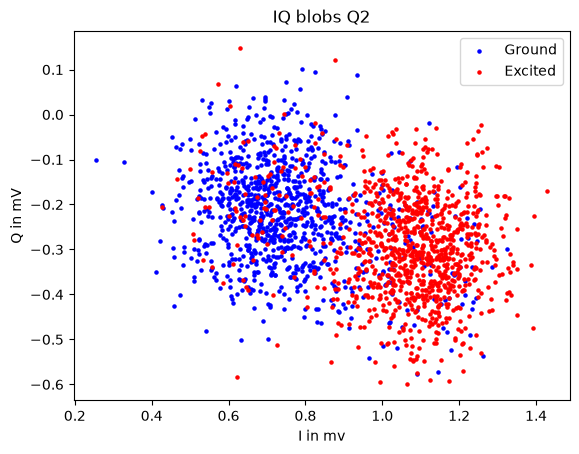

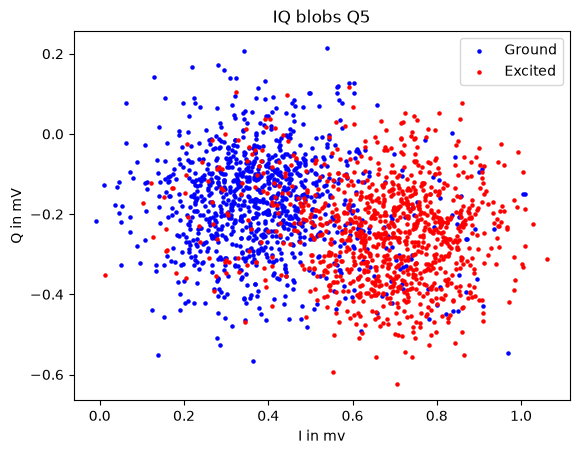

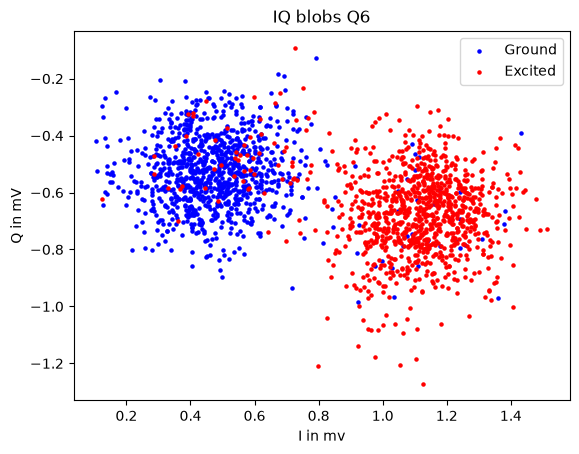

In [39]:
def load_data(path, qubit, onlyTrain=0) :
    ds=load_iq(path)
    (g,e)=iq_samples(ds,qubit)
    g=g*1000 #convert to mv
    e=e*1000
    if onlyTrain:
        return (g[:500,0],g[:500,1],e[:500,0],e[:500,1])
    else:
        return (g[:,0],g[:,1],e[:,0],e[:,1])
    
    
# Write your IQ plotting code here.
def plot_one(path, qubit, dotsize) :
    (gi,gq,ei,eq)=load_data(path,qubit)
     
    # Create scatter plots in mv
    plt.scatter(gi, gq,color='blue', s=dotsize,label='Ground')
    plt.scatter(ei, eq,color='red', s=dotsize, label='Excited')
    
    # Add labels and title
    plt.xlabel("I in mv")
    plt.ylabel("Q in mV")
    plt.title("IQ blobs " +qubit)
    
    # Display the plot
    plt.legend()
    plt.show()
dotsize=5
for run in RUNS:
    plot_one(run["path"],run["qubit"],dotsize)

## 2. Build and evaluate a discriminator (7 points)

### 2(a): choose a projection (2 points)
Use each qubit's **training** centroids to construct an angle theta so that `x = I*cos(theta) + Q*sin(theta)` lies along their separation, with the e centroid at larger x. Explain the construction and report theta. Use `splits[qubit]['train_g']` and `splits[qubit]['train_e']` to fit the rule; keep it fixed on the test data.

**Construction and angles:**

In [41]:
# Compute the training centroids and discrimination axis for each qubit.
# the parameters are data for ground I, ground Q, excited I, excited Q
def comp_centroids_theta(path, qubit):
    gi, gq, ei, eq = load_data(path, qubit)
    gi_avg = np.mean(gi)
    gq_avg = np.mean(gq)
    ei_avg = np.mean(ei)
    eq_avg = np.mean(eq)
    theta = -np.arctan2(eq_avg-gq_avg, ei_avg-gi_avg)
    print(f"\nQubit {qubit}")
    print(f"Ground centroid  = ({gi_avg}, {gq_avg})")
    print(f"Excited centroid  = ({ei_avg}, {eq_avg})")
    print(f"theta = {theta}")
    return

for run in RUNS:
    comp_centroids_theta(run["path"],run["qubit"])
    


Qubit Q2
Ground centroid  = (0.7539369430541992, -0.22142398071289063)
Excited centroid  = (1.054194580078125, -0.2903538131713867)
theta = 0.2256589626791023

Qubit Q5
Ground centroid  = (0.39303404998779295, -0.17440069580078124)
Excited centroid  = (0.6704523239135742, -0.2468551559448242)
theta = 0.25546747363834194

Qubit Q6
Ground centroid  = (0.4898628997802734, -0.533719825744629)
Excited centroid  = (1.0859023666381835, -0.6680034408569336)
theta = 0.22159345895376978


### 2(b): choose and apply the threshold (2 points)
Assign e for `x >= t`, and g otherwise. Minimize the training balanced error defined in the handout. A search over intervals between sorted distinct projected values, plus the constant-classifier limits, is sufficient. Explain your search and handling of ties.

Project the test data along the **fixed training axis** and make overlaid test histograms, marking the **fixed training threshold**. Report threshold units.

**Threshold method and values:**

In [ ]:
# Fit thresholds using training samples; plot held-out histograms.

### 2(c): confusion matrix and assignment performance (3 points)
For each qubit, report held-out g-to-e and e-to-g error counts and the sample count in each class. Construct the matrix with **rows = intended preparation [g, e]** and **columns = reported state [g, e]**, normalizing each row separately. Calculate the average of its diagonal entries.

Compare your held-out result with the node's all-data fit/evaluation. The node's `readout_fidelity` is a percentage, while its confusion matrix entries are probabilities.

**Results and comparison:**

In [ ]:
# Compute error counts, row-normalized matrices, and assignment accuracies.

## 3. Connect to readout physics (4 points)

### 3(a) (2 points)
Using test projections and the fixed axis, compute the mean separation divided by the square root of the sum of the two sample variances. In NumPy, use `np.var(..., ddof=1)` for each sample variance. Report this SNR alongside assignment accuracy for both qubits.

Relate the mean separation to written HW4's state-dependent resonator response. Why is raw separation alone insufficient to rank readout? Does rotating stored IQ data change the physical measurement?

**Answer:**

In [ ]:
# Calculate held-out SNRs and summarize the results for the two qubits.

### 3(b) (2 points)
Why is the observed assignment accuracy neither isolated measurement fidelity nor gate fidelity? Identify one preparation effect and one effect during readout that contribute to errors. For one, propose a diagnostic and its expected signature; no additional hardware run is required.

**Answer:**

## Submission check
- Two qubits, raw data, run parameters, and experimental record.
- Labeled equal-axis IQ scatter plots.
- Training-only axes and thresholds, with your explanation.
- Test histograms, error counts, matrices, assignment accuracies, and SNRs.
- Written physics interpretation and proposed diagnostic.
- Rerun your notebook from a fresh kernel and include its outputs with the submission.